# Assignment 1 — EDA & Baseline
## The Pokémon Company – PTCG AI Battle Challenge Playground

**Group:** GROUP06 — Enes İnançlı, Berat Orkun Elibol, Bengi Kayra Özdemir &nbsp;·&nbsp; **Course:** CENG313 &nbsp;·&nbsp; **Competition:** <https://www.kaggle.com/competitions/the-pokemon-company-ptcg-ai-battle-challenge-playground>

This notebook tells the story; the reusable code lives in `src/` (`data.py` – loading, cleaning, simulation;
`models.py` – agents, evaluation, win-probability model; `utils.py` – plotting, metrics, submission bundle).

**Contents**
1. Problem definition
2. Data overview
3. Exploratory data analysis
4. Preprocessing
5. Baseline model
6. Kaggle submission
7. Conclusion

> **Data & rules note.** The competition data (card metadata, simulator, sample submission) is *not* committed — it lives in
> `data/` which is git-ignored. Card names and texts are "Pokémon Elements" under the competition rules, so this repository must stay private
> to the course organisation.

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data, models, utils
from src.utils import PALETTE, GRAY

utils.set_seed(42)
utils.setup_plotting()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Number of simulated games per experiment. Lower these for a quick run.
N_EDA_GAMES = 600       # random vs random (gameplay EDA)
N_TUNE_GAMES = 150      # per heuristic configuration (training games)
N_VALID_GAMES = 400     # fresh validation games per opponent
N_VALUE_GAMES = 500     # heuristic self-play games for the win-probability model

## 1. Problem definition

**Task.** Build an *agent* that plays the Pokémon Trading Card Game (PTCG) inside the official `cabt` simulator.
It is a **simulation competition**: there is no `train.csv`/`test.csv`. We submit code; Kaggle makes it play
best-of-three (BO3) matches against other teams' agents.

**How the agent works.** The agent is a function `agent(obs) -> list[int]`:
* on the first call (`obs["select"] is None`) it returns its **60-card deck**;
* afterwards, every time the engine needs a decision it sends the board state, recent logs and a list of **legal options**
  (play a card, attach Energy, evolve, retreat, attack, end turn, choose targets …). The agent returns the indices of the
  options it picks (between `minCount` and `maxCount` of them). An illegal answer, an exception or a time-out loses the whole match.

**Target.** Winning the match. Each episode gives reward +1 (win), −1 (loss) or 0 (draw).
A player wins a game by taking all 6 Prize cards, when the opponent cannot draw at the start of their turn, or when the
opponent has no Pokémon left to put in the Active Spot.

**Evaluation metric (Kaggle).** Every submission has a skill rating modelled as a Gaussian N(μ, σ²). New submissions start at
**μ₀ = 600**; after every episode the winner's μ goes up and the loser's goes down, by an amount that depends on how surprising the
result was and on σ. The final leaderboard comes from a **Bradley–Terry tournament** on the episodes played. Only the latest two
submissions per team stay active.

**Our local (offline) metric.** The ladder needs other people's agents, so offline we measure:
* **win rate** against reference agents, with a **Wilson 95 % confidence interval** (games are random, so a single number is not enough);
* a **Bradley–Terry rating** of our local agent pool on an Elo-like scale (the same model Kaggle uses for the final ranking).

**Data we have.**
1. `EN_Card_Data_R2_full.csv` – metadata for every card in the card pool (one row per card × move).
2. The simulator itself (`kaggle-environments`, environment `cabt`) – we generate our own gameplay data by playing games.
3. `sample_submission/` – a working agent and a sample 60-card deck (`deck.csv`), which our baseline also uses.

## 2. Data overview
### 2.1 Card metadata (`EN_Card_Data_R2_full.csv`)

We load every column as text first (`keep_default_na=False`). The file marks missing values in two ways — the literal
string `n/a` and an **empty cell** — and the default `pd.read_csv` would silently turn both into `NaN`. As the checks below
show, *what* a blank means depends on the kind of card, so we keep the raw markers until we know.

In [2]:
raw = data.load_raw_cards()
print("shape:", raw.shape)
raw.head(8)

shape: (2273, 18)


,Card ID,Card Name,Expansion,Collection No.,Stage (Pokémon)/Type (Energy and Trainer),Rule,Category,Previous stage,HP,Type,Weakness,Resistance (Type),Retreat,Move Name,Cost,Damage,Effect Explanation,Species
0,1,Basic {G} Energy,SVE,1,Basic Energy,n/a,n/a,n/a,n/a,{G},,,n/a,,n/a,n/a,,n/a
1,2,Basic {R} Energy,SVE,2,Basic Energy,n/a,n/a,n/a,n/a,{R},,,n/a,,n/a,n/a,,n/a
2,3,Basic {W} Energy,SVE,3,Basic Energy,n/a,n/a,n/a,n/a,{W},,,n/a,,n/a,n/a,,n/a
3,4,Basic {L} Energy,SVE,4,Basic Energy,n/a,n/a,n/a,n/a,{L},,,n/a,,n/a,n/a,,n/a
4,5,Basic {P} Energy,SVE,5,Basic Energy,n/a,n/a,n/a,n/a,{P},,,n/a,,n/a,n/a,,n/a
5,6,Basic {F} Energy,SVE,6,Basic Energy,n/a,n/a,n/a,n/a,{F},,,n/a,,n/a,n/a,,n/a
6,7,Basic {D} Energy,SVE,7,Basic Energy,n/a,n/a,n/a,n/a,{D},,,n/a,,n/a,n/a,,n/a
7,8,Basic {M} Energy,SVE,8,Basic Energy,n/a,n/a,n/a,n/a,{M},,,n/a,,n/a,n/a,,n/a


In [3]:
# dtypes as read (all text on purpose) and the dtypes pandas would infer
inferred = pd.read_csv(data.find_file("EN_Card_Data*.csv"), encoding="utf-8-sig").dtypes
pd.DataFrame({"as_loaded": raw.dtypes.astype(str), "pandas_default": inferred.astype(str)})

,as_loaded,pandas_default
Card ID,str,int64
Card Name,str,str
Expansion,str,str
Collection No.,str,int64
Stage (Pokémon)/Type (Energy and Trainer),str,str
Rule,str,str
Category,str,str
Previous stage,str,str
HP,str,float64
Type,str,str


In [4]:
# describe(): numeric view of the columns that should be numbers + text summary
num_view = raw[["HP", "Retreat", "Collection No."]].replace({"n/a": np.nan, "": np.nan}).apply(pd.to_numeric)
display(num_view.describe().T.round(1))
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
HP,2044.0,131.0,73.5,30.0,70.0,110.0,150.0,380.0
Retreat,1969.0,1.8,0.9,1.0,1.0,2.0,2.0,4.0
Collection No.,2273.0,67.4,47.1,1.0,29.0,59.0,98.0,215.0


,count,unique,top,freq
Card ID,2273,1431,30,3
Card Name,2273,1196,Eevee,6
Expansion,2273,22,DRI,279
Collection No.,2273,197,6,26
Stage (Pokémon)/Type (Energy and Trainer),2273,9,Basic Pokémon,1073
Rule,2273,4,n/a,1889
Category,2273,26,n/a,1877
Previous stage,2273,393,n/a,1302
HP,2273,36,70,308
Type,2273,15,{G},278


In [5]:
# Missing values: two different kinds of "missing"
missing = pd.DataFrame({
    "n/a (not applicable)": (raw == "n/a").sum(),
    "empty (none / missing)": (raw == "").sum(),
})
missing["total %"] = (missing.sum(axis=1) / len(raw) * 100).round(1)
display(missing.sort_values("total %", ascending=False))

# Which kind of card do the blanks belong to?
kind = raw["Stage (Pokémon)/Type (Energy and Trainer)"].map(data.supertype)
rows = {}
for col in ["HP", "Weakness", "Resistance (Type)", "Retreat", "Cost"]:
    for marker, label in [("n/a", "n/a"), ("", "empty")]:
        rows[(col, label)] = kind[raw[col] == marker].value_counts()
pd.DataFrame(rows).T.fillna(0).astype(int)

,n/a (not applicable),empty (none / missing),total %
Species,2067,0,90.9
Rule,1889,0,83.1
Category,1877,0,82.6
Resistance (Type),1590,240,80.5
Previous stage,1302,0,57.3
Damage,826,0,36.3
Effect Explanation,594,8,26.5
Cost,518,0,22.8
Weakness,80,240,14.1
Retreat,304,0,13.4


Stage (Pokémon)/Type (Energy and Trainer)  Energy  Pokémon  Trainer
HP                n/a                          25        0      204
                  empty                         0        0        0
Weakness          n/a                           0       77        3
                  empty                        25        0      215
Resistance (Type) n/a                           0     1587        3
                  empty                        25        0      215
Retreat           n/a                          25       61      218
                  empty                         0        0        0
Cost              n/a                          25      276      217
                  empty                         0        0        0

In [6]:
# Duplicates
print("fully duplicated rows        :", raw.duplicated().sum())
print("rows                         :", len(raw))
print("unique Card IDs              :", raw["Card ID"].nunique())
print("duplicated (Card ID, Move)   :", raw.duplicated(["Card ID", "Move Name"]).sum())
print("rows per card                :", raw["Card ID"].value_counts().value_counts().sort_index().to_dict())
same_name = raw.drop_duplicates("Card ID").groupby("Card Name")["Card ID"].nunique()
print("names shared by >1 Card ID   :", (same_name > 1).sum(), "(reprints / alternate versions)")

fully duplicated rows        : 0
rows                         : 2273
unique Card IDs              : 1431
duplicated (Card ID, Move)   : 0
rows per card                : {1: 621, 2: 778, 3: 32}
names shared by >1 Card ID   : 196 (reprints / alternate versions)


**Interpretation.** The table has 2,273 rows × 18 columns but only **1,431 unique Card IDs**: it is in *long format* — one row per
card × move (621 cards have 1 row, 778 have 2, 32 have 3). Repeated Card IDs are therefore by design, not duplicates: there are
**no fully duplicated rows** and no repeated (Card ID, Move) pair. 196 card names belong to several IDs (reprints / alternate
versions with different stats), so we always key on `Card ID`, never on the name.

Missingness is almost entirely **structural**. Species, Rule and Category are filled only for the few cards that have them;
HP is `n/a` exactly for Trainers and Energy. The supertype table shows that the two markers are used *inconsistently*:
Trainers/Energy have an **empty** Weakness/Resistance, while on **Pokémon** the same columns say `n/a` — and for a Pokémon that
means "has no Weakness/Resistance" (77 rows, e.g. Dragon types). Likewise 61 Pokémon rows have `n/a` retreat, i.e. a *free*
retreat. The same marker therefore means different things for different rows, which drives the preprocessing in Section 4.
Numerically, HP spans 30–380 with mean 131 > median 110 (right-skewed) and retreat cost is 1–4 (plus the free ones).

### 2.2 Engine card & attack tables

Observations refer to attacks by an **`attackId`**, which the CSV does not contain. The simulator library exposes its own
card and attack tables (`AllCard`, `AllAttack`), so we load them and check that they agree with the CSV.

In [7]:
engine_cards, engine_attacks = data.load_engine_tables()
print("engine cards  :", engine_cards.shape, "| engine attacks:", engine_attacks.shape)
print("same card IDs as the CSV:", set(engine_cards["cardId"]) == set(raw["Card ID"].astype(int)))
engine_attacks.head()

engine cards  : (1431, 20) | engine attacks: (1755, 5)
same card IDs as the CSV: True


,attackId,name,text,damage,energies
0,1,Nab ’n’ Dash,Search your deck for a number of cards up to t...,0,[0]
1,2,High Jump Kick,,100,"[7, 0, 0]"
2,3,Push Down,Switch out your opponent’s Active Pokémon to t...,10,[6]
3,4,Ram,,60,"[6, 6]"
4,5,Super Sandstorm,This attack also does 40 damage to each Benche...,150,"[6, 6, 0]"


### 2.3 Simulated gameplay data

We generate our own tabular data by letting two **random agents** (uniformly random legal moves, both using the sample deck)
play single games. Every game is parsed from the simulator's full-information replay (`env.steps[0][0]["visualize"]` – the same
format Kaggle uses for episode replays) into three tables:

* `games` – one row **per player per game** (target column `won`) with simple counts: attacks, damage dealt, attachments, evolutions …
* `decisions` – one row per decision the engine asked for (decision type, number of legal options …)
* `snapshots` – the board at the start of every turn (used later for the win-probability model).

Random-vs-random games are the "null model" of the game: they show the mechanics (game length, first-player advantage,
branching factor) without any strategy on top.

In [8]:
deck = data.read_deck()            # sample deck from the competition data
rand_a, rand_b = models.RandomPolicy(deck, seed=1), models.RandomPolicy(deck, seed=2)
games_r, dec_r, snap_r = data.simulate_games(models.as_kaggle_agent(rand_a), models.as_kaggle_agent(rand_b),
                                             N_EDA_GAMES, names=("random_A", "random_B"))
print(games_r.shape, dec_r.shape, snap_r.shape)
games_r.head()

  120/600 games  (20s)


  240/600 games  (41s)


  360/600 games  (61s)


  480/600 games  (83s)


  600/600 games  (103s)
(1200, 20) (28822, 9) (8138, 29)


,game_id,player,agent,opponent,went_first,won,draw,end_reason,n_turns,prizes_taken,attacks,damage_dealt,attachments,evolutions,cards_played,switches,decisions,main_decisions,options_seen,status
0,0,0,random_A,random_B,True,1,0,Opponent has no Active Pokémon,13,2,3,470,6,1,4,0,28,17,127,DONE
1,0,1,random_B,random_A,False,0,0,Opponent has no Active Pokémon,13,1,3,200,5,0,0,0,17,11,99,DONE
2,1,0,random_B,random_A,False,1,0,Opponent has no Active Pokémon,18,5,7,2040,7,1,4,0,31,19,173,DONE
3,1,1,random_A,random_B,True,0,0,Opponent has no Active Pokémon,18,0,4,170,9,0,4,1,33,23,173,DONE
4,2,0,random_A,random_B,False,1,0,Opponent has no Active Pokémon,6,1,3,130,3,0,0,0,12,6,62,DONE


In [9]:
display(games_r.dtypes.to_frame("dtype").T)
display(games_r.describe().T.round(2))
print("missing values per table:", games_r.isna().sum().sum(), dec_r.isna().sum().to_dict())
print("duplicated (game_id, player) rows:", games_r.duplicated(["game_id", "player"]).sum())
print("episode statuses:", games_r["status"].value_counts().to_dict())

,game_id,player,agent,opponent,went_first,won,draw,end_reason,n_turns,prizes_taken,attacks,damage_dealt,attachments,evolutions,cards_played,switches,decisions,main_decisions,options_seen,status
dtype,int64,int64,str,str,bool,int64,int64,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str


,count,mean,std,min,25%,50%,75%,max
game_id,1200.0,299.50,173.28,0.0,149.75,299.5,449.25,599.0
player,1200.0,0.50,0.50,0.0,0.00,0.5,1.00,1.0
won,1200.0,0.50,0.50,0.0,0.00,0.5,1.00,1.0
draw,1200.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
n_turns,1200.0,13.56,8.35,3.0,7.75,11.5,18.00,51.0
prizes_taken,1200.0,1.58,1.80,0.0,0.00,1.0,3.00,6.0
attacks,1200.0,3.18,2.30,0.0,1.00,3.0,4.00,15.0
damage_dealt,1200.0,400.07,407.69,0.0,70.00,260.0,600.00,2040.0
attachments,1200.0,6.08,4.05,0.0,3.00,5.0,8.00,28.0
evolutions,1200.0,0.85,0.83,0.0,0.00,1.0,1.00,4.0


missing values per table: 0 {'game_id': 0, 'player': 0, 'turn': 0, 'select_type': 0, 'context': 0, 'n_options': 0, 'min_count': 0, 'max_count': 0, 'chosen_type': 7613}
duplicated (game_id, player) rows: 0
episode statuses: {'DONE': 1200}


**Interpretation.** 600 random-vs-random games give 1,200 player-game rows (20 columns), 28,822 decision rows and 8,138 turn snapshots.
All columns have the expected types (counts are integers, `went_first` boolean, names/reasons strings), every episode finished
normally (`DONE`, no agent errors), there are no duplicated (game, player) rows and no missing values — except `chosen_type`
in the decision table, which is only defined when exactly one option is chosen (multi-select decisions such as benching
several Pokémon leave it empty by construction). The target `won` is perfectly balanced at 0.50 because every game has one
winner and one loser (no draws occurred). `describe()` already hints at the game's shape: a typical game lasts ~11 turns,
but some go past 50; damage dealt ranges from 0 to 2,040.

## 3. Exploratory data analysis
### 3.1 Card pool
We use the cleaned, typed tables from Section 4 (`clean_moves` → one row per card × move, `card_level_table` → one row per card)
so the plots read numbers instead of strings. The cleaning itself is explained in Section 4.

cards: (1431, 24) | Pokémon: 1196


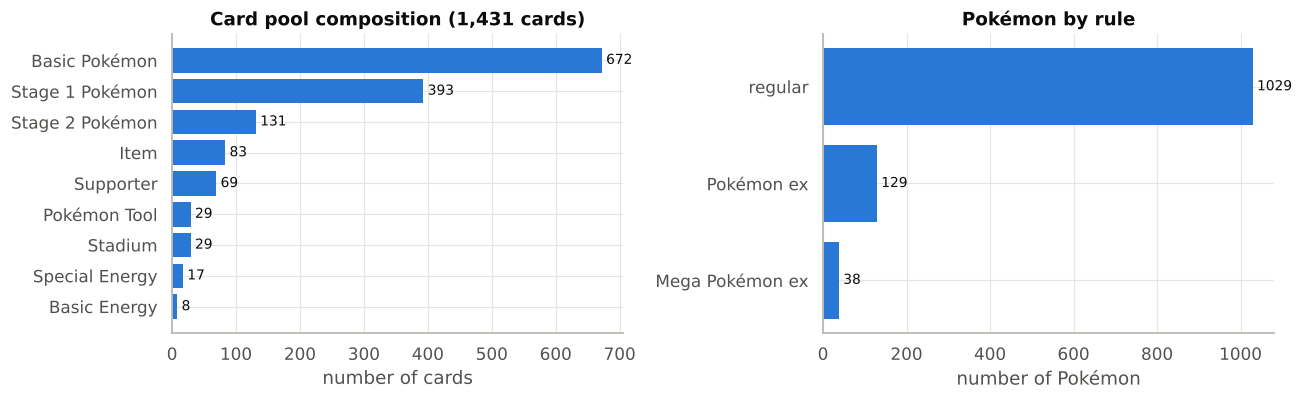

In [10]:
moves = data.clean_moves(raw)
cards = data.card_level_table(moves)
pokemon = cards[cards["supertype"] == "Pokémon"].copy()
print("cards:", cards.shape, "| Pokémon:", len(pokemon))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
comp = cards["stage"].value_counts()
utils.bar_with_labels(axes[0], comp)
axes[0].set_title("Card pool composition (1,431 cards)")
axes[0].set_xlabel("number of cards")
rules = pokemon["rule"].fillna("regular").value_counts()
utils.bar_with_labels(axes[1], rules, color=PALETTE[0])
axes[1].set_title("Pokémon by rule")
axes[1].set_xlabel("number of Pokémon")
plt.tight_layout(); plt.show()

**Interpretation.** Pokémon dominate the pool (1,196 of 1,431 cards: 672 Basic, 393 Stage 1, 131 Stage 2), against only 83 Items,
69 Supporters, 29 Tools, 29 Stadiums and 25 Energy cards. Deck building is therefore mostly a choice *among Pokémon*. 14 % of
the Pokémon are **ex** (129) or **Mega ex** (38); these give the opponent 2 or 3 Prize cards when knocked out instead of 1 — a
trade-off between power and risk that a good agent has to weigh.

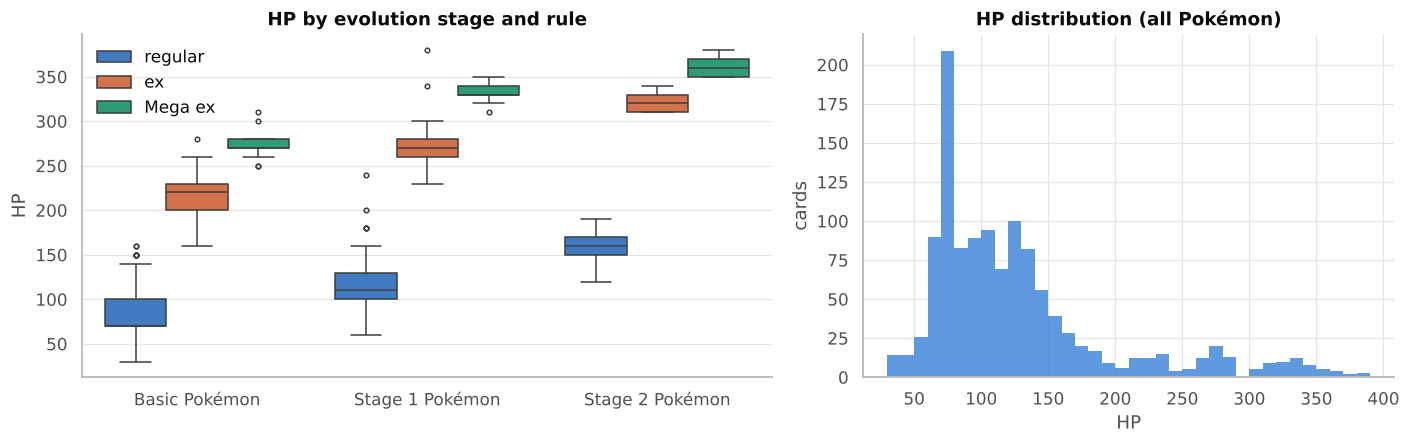

IQR rule: HP > 245 is an outlier -> 108 cards, of which 100% are ex / Mega ex


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
Mega ex,38.0,322.0,39.0,250.0,280.0,330.0,350.0,380.0
ex,129.0,255.0,47.0,160.0,220.0,260.0,280.0,380.0
regular,1029.0,98.0,34.0,30.0,70.0,90.0,120.0,240.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
order = ["Basic Pokémon", "Stage 1 Pokémon", "Stage 2 Pokémon"]
pokemon["kind"] = np.where(pokemon["is_mega_ex"], "Mega ex", np.where(pokemon["is_ex"], "ex", "regular"))
sns.boxplot(data=pokemon, x="stage", y="hp", hue="kind", order=order, hue_order=["regular", "ex", "Mega ex"],
            palette=PALETTE[:3], ax=axes[0], fliersize=3, linewidth=1)
axes[0].set_title("HP by evolution stage and rule"); axes[0].set_xlabel(""); axes[0].set_ylabel("HP")
axes[0].legend(title="", frameon=False)
sns.histplot(pokemon["hp"], bins=range(30, 400, 10), color=PALETTE[0], ax=axes[1], edgecolor="white")
axes[1].set_title("HP distribution (all Pokémon)"); axes[1].set_xlabel("HP"); axes[1].set_ylabel("cards")
plt.tight_layout(); plt.show()

q1, q3 = pokemon["hp"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
out = pokemon[pokemon["hp"] > upper]
print(f"IQR rule: HP > {upper:.0f} is an outlier -> {len(out)} cards, of which {out['is_ex'].mean():.0%} are ex / Mega ex")
pokemon.groupby("kind")["hp"].describe().round(0)

**Interpretation.** HP rises clearly with evolution stage and with the rule: regular Pokémon have a median of 90 HP, ex 260 and Mega ex
330. The overall distribution is right-skewed and multi-modal (most cards at 60–150 HP, smaller bumps around 220–280 and
320–360). The IQR rule flags **108 cards above 245 HP** as outliers, but **100 % of them are ex / Mega ex**: they are a separate
population, not data errors. We keep them; `is_ex` and the stage explain them far better than clipping would.

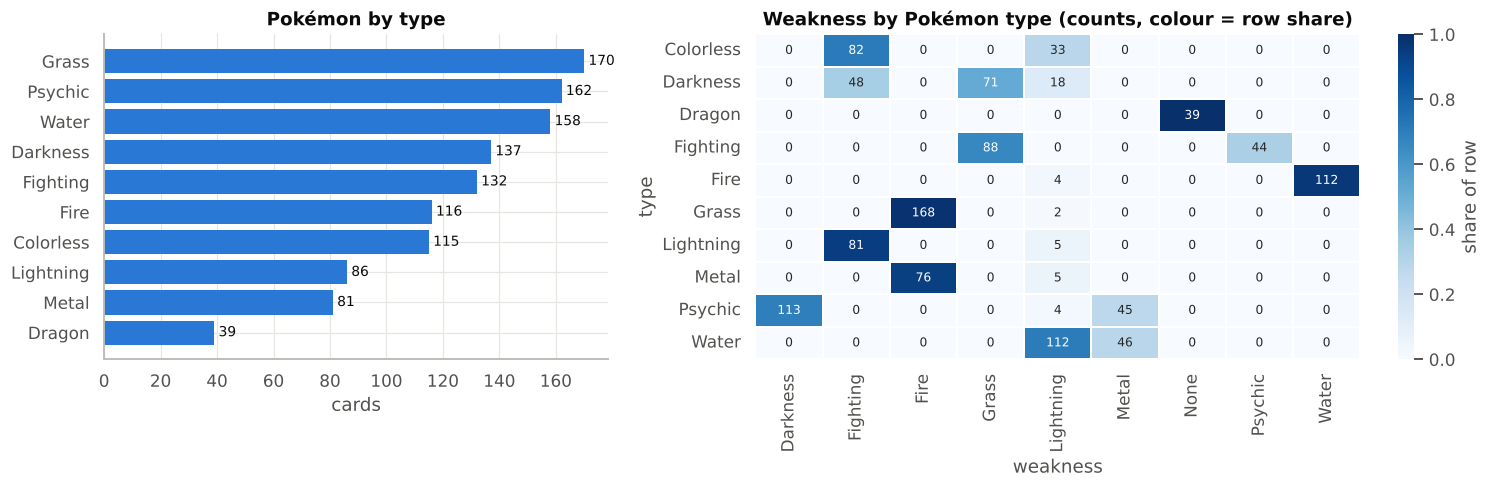

In [12]:
type_counts = pokemon["type"].value_counts()
weak = pd.crosstab(pokemon["type"], pokemon["weakness"].fillna("None"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
utils.bar_with_labels(axes[0], type_counts)
axes[0].set_title("Pokémon by type"); axes[0].set_xlabel("cards")
sns.heatmap(weak.div(weak.sum(axis=1), axis=0), cmap="Blues", annot=weak, fmt="d", cbar_kws={"label": "share of row"},
            linewidths=1, linecolor="white", ax=axes[1], annot_kws={"fontsize": 8})
axes[1].set_title("Weakness by Pokémon type (counts, colour = row share)")
axes[1].set_xlabel("weakness"); axes[1].set_ylabel("type")
plt.tight_layout(); plt.show()

**Interpretation.** The types are fairly balanced (Grass 170 … Dragon 39). The Weakness map is almost one-to-one: Grass→Fire,
Fire→Water, Lightning→Fighting, Metal→Fire, Psychic mostly→Darkness, Water mostly→Lightning, and Dragons have **no** Weakness.
Because Weakness doubles the damage taken, the attacker's type versus the opponent's Active Pokémon matters a lot. Our agent uses
this: it applies ×2 for Weakness and −30 for Resistance when it ranks attacks.

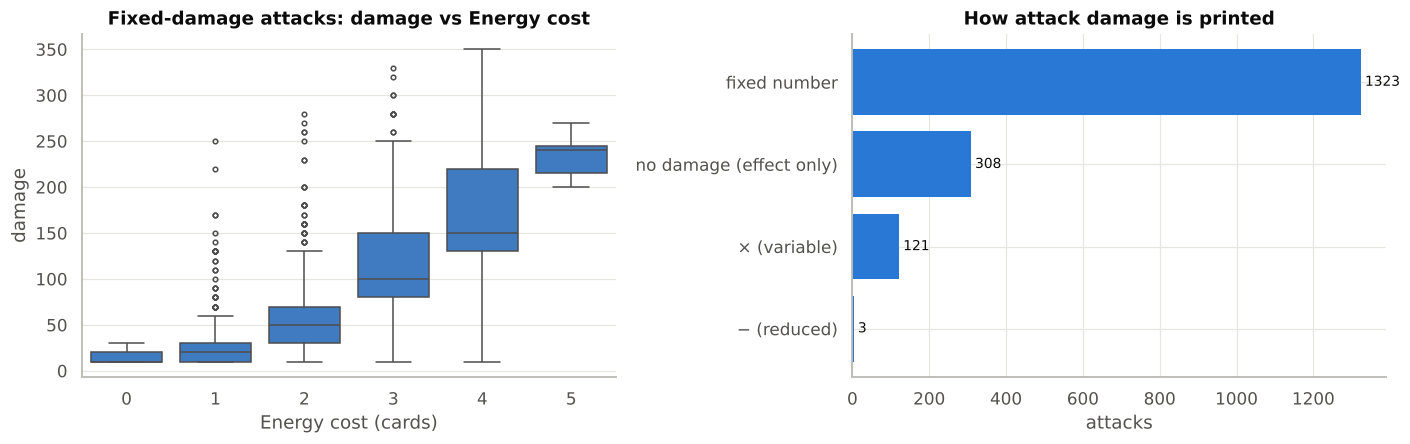

median damage by cost: {0: 10.0, 1: 20.0, 2: 50.0, 3: 100.0, 4: 150.0, 5: 240.0}
Spearman rho(cost, damage) = 0.724


In [13]:
atk = moves[moves["is_attack"]].copy()
fixed = atk[atk["damage_mod"] == "fixed"].astype({"cost_total": int})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=fixed, x="cost_total", y="damage_base", color=PALETTE[0], ax=axes[0], fliersize=3, linewidth=1)
med = fixed.groupby("cost_total")["damage_base"].median()
axes[0].set_title("Fixed-damage attacks: damage vs Energy cost")
axes[0].set_xlabel("Energy cost (cards)"); axes[0].set_ylabel("damage")
mods = atk["damage_mod"].replace({"fixed": "fixed number", "none": "no damage (effect only)", "x": "× (variable)", "-": "− (reduced)"})
utils.bar_with_labels(axes[1], mods.value_counts())
axes[1].set_title("How attack damage is printed"); axes[1].set_xlabel("attacks")
plt.tight_layout(); plt.show()
print("median damage by cost:", med.to_dict())
print("Spearman rho(cost, damage) =", round(fixed[["cost_total", "damage_base"]].corr("spearman").iloc[0, 1], 3))

**Interpretation.** Damage grows steadily with the Energy cost (median 20 → 50 → 100 → 150 → 240 for 1–5 Energy; Spearman ρ = 0.72), i.e.
roughly +50 damage per extra Energy. Within each cost the spread is wide, with many high outliers (up to 250 damage for a single
Energy). These are usually attacks with a drawback in the effect text, so the printed number alone over-rates them. 308 attacks
print no damage at all (pure effects) and **121 have variable damage** (`30×`). For those the engine's attack table reports 0, so
we need our own estimate (Section 4).

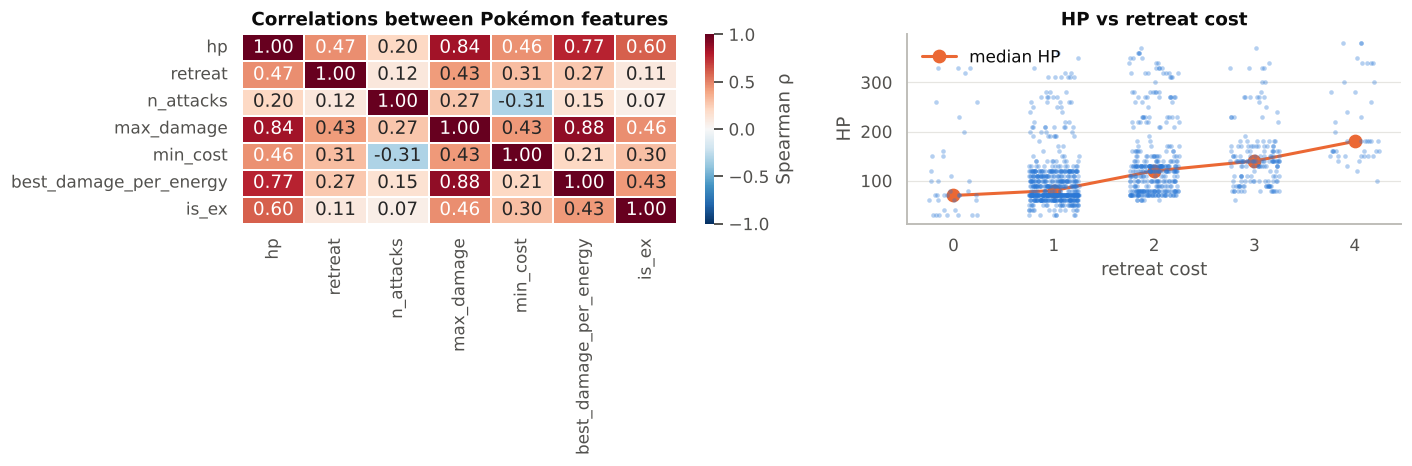

In [14]:
num_cols = ["hp", "retreat", "n_attacks", "max_damage", "min_cost", "best_damage_per_energy"]
corr = pokemon[num_cols + ["is_ex"]].astype(float).corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], linewidths=1, linecolor="white",
            cbar_kws={"label": "Spearman ρ"})
axes[0].set_title("Correlations between Pokémon features")
pokemon["retreat"] = pokemon["retreat"].astype(int)
ret = pokemon.groupby("retreat")["hp"].median()
sns.stripplot(data=pokemon, x="retreat", y="hp", color=PALETTE[0], alpha=0.35, size=3, jitter=0.25, ax=axes[1])
axes[1].plot(range(len(ret)), ret.values, color=PALETTE[1], marker="o", markersize=8, label="median HP")
axes[1].set_title("HP vs retreat cost"); axes[1].set_xlabel("retreat cost"); axes[1].set_ylabel("HP")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.** HP is strongly related to the best attack (ρ = 0.84 with max damage) and to being ex (0.60): bigger Pokémon also hit
harder. Retreat cost grows with HP (median HP ≈ 70 at cost 0 → ≈ 180 at cost 4), so bulky attackers are expensive to move out of
the Active Spot. `n_attacks` is negatively related to `min_cost` (−0.31): Pokémon with two attacks usually have a cheap one.
`max_damage` and `best_damage_per_energy` are nearly redundant (0.88), so only one of them belongs in a linear model.

In [15]:
deck_df = (pd.Series(deck).value_counts().rename("copies").to_frame()
           .join(cards.set_index("card_id")[["name", "stage", "hp", "type"]]))
display(deck_df)
print("Basic Pokémon in deck:", int(deck_df.loc[deck_df["stage"] == "Basic Pokémon", "copies"].sum()), "/ 60")
from math import comb
n_basic = int(deck_df.loc[deck_df["stage"] == "Basic Pokémon", "copies"].sum())
p0 = comb(60 - n_basic, 7) / comb(60, 7)
p1 = n_basic * comb(60 - n_basic, 6) / comb(60, 7)
print(f"P(no Basic in opening 7) = {p0:.1%}  (mulligan)   P(exactly one Basic | not mulligan) = {p1 / (1 - p0):.1%}")

,copies,name,stage,hp,type
3,35,Basic {W} Energy,Basic Energy,NaN,Water
722,4,Snover,Basic Pokémon,90.0,Water
723,4,Mega Abomasnow ex,Stage 1 Pokémon,350.0,Water
1145,4,Mega Signal,Item,NaN,NaN
1227,4,Lillie's Determination,Supporter,NaN,NaN
1235,4,Waitress,Supporter,NaN,NaN
721,2,Kyogre,Basic Pokémon,150.0,Water
1205,2,Cyrano,Supporter,NaN,NaN
1158,1,Maximum Belt,Pokémon Tool,NaN,NaN


Basic Pokémon in deck: 6 / 60
P(no Basic in opening 7) = 45.9%  (mulligan)   P(exactly one Basic | not mulligan) = 74.1%


**Interpretation.** The sample deck (which our baseline also uses) is a mono-Water deck: 35 Basic Water Energy, only **6 Basic Pokémon**
(2 Kyogre, 4 Snover), 4 Mega Abomasnow ex (evolves from Snover, 350 HP) and 15 Trainers. With 6 Basics, the hypergeometric
probability of an opening hand **without** a Basic is 45.9 % (mulligan). When we do have one, it is the only one 74 % of the time.
A player loses as soon as they have no Pokémon left in play, so this deck is fragile. That explains why most games below end by
"no Active Pokémon", and it makes the deck an obvious lever for Assignment 2.

### 3.2 Gameplay (random vs random)

games                      600.000
seat 0 win rate              0.473
draws                        0.000
player going first wins      0.540
95% CI for first-player win rate: [0.500, 0.579]


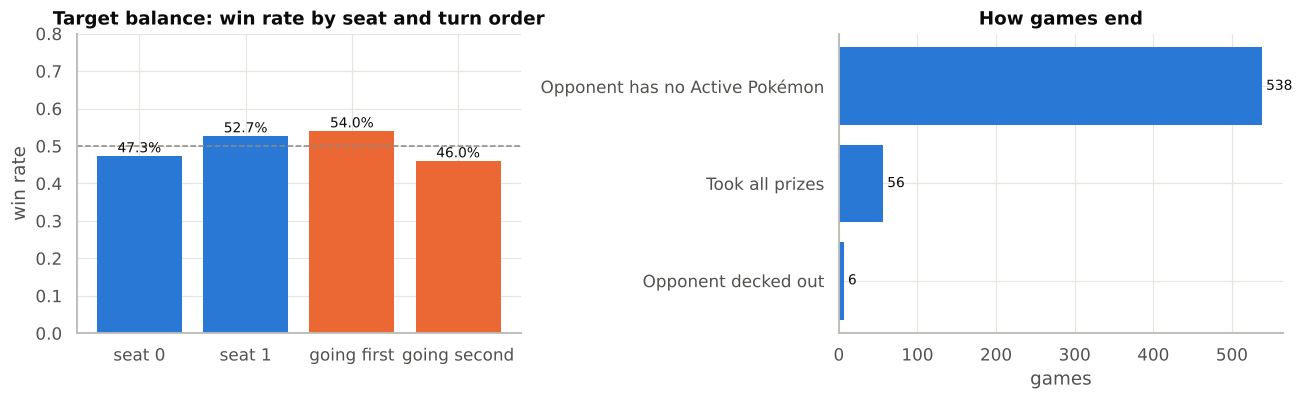

In [16]:
seat0 = games_r[games_r["player"] == 0]
first = games_r[games_r["went_first"]]
summary = pd.Series({
    "games": len(seat0),
    "seat 0 win rate": seat0["won"].mean(),
    "draws": seat0["draw"].mean(),
    "player going first wins": first["won"].mean(),
})
lo, hi = utils.wilson_ci(first["won"].sum(), len(first))
print(summary.round(3).to_string()); print(f"95% CI for first-player win rate: [{lo:.3f}, {hi:.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
wr = pd.Series({"seat 0": seat0["won"].mean(), "seat 1": 1 - seat0["won"].mean() - seat0["draw"].mean(),
                "going first": first["won"].mean(), "going second": games_r.loc[~games_r["went_first"], "won"].mean()})
axes[0].bar(wr.index, wr.values, color=[PALETTE[0], PALETTE[0], PALETTE[1], PALETTE[1]])
for i, v in enumerate(wr.values):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=9)
axes[0].axhline(0.5, color=GRAY, ls="--", lw=1)
axes[0].set_ylim(0, 0.8); axes[0].set_title("Target balance: win rate by seat and turn order"); axes[0].set_ylabel("win rate")
utils.bar_with_labels(axes[1], seat0["end_reason"].value_counts())
axes[1].set_title("How games end"); axes[1].set_xlabel("games")
plt.tight_layout(); plt.show()

**Interpretation.** **Target balance.** Seat 0 wins 47.3 % and seat 1 52.7 %, so the seat itself carries no advantage beyond noise. The
player **going first wins 54.0 %** (95 % CI 50.0–57.9 %): a small first-player edge, borderline significant with random play.
This matches the fact that random agents choose to go first only half of the time. The classes are balanced, so accuracy-type
metrics are not misleading, and **seats must still be alternated** in every evaluation.

**How games end.** 538 of 600 games (90 %) end because a player has **no Pokémon left to put in the Active Spot**. Only 56 end by
taking all six Prize cards and 6 by deck-out. With few Basics and no bench-building, the first knock-out is often decisive.
Keeping Pokémon on the Bench is therefore the first thing a better agent should do.

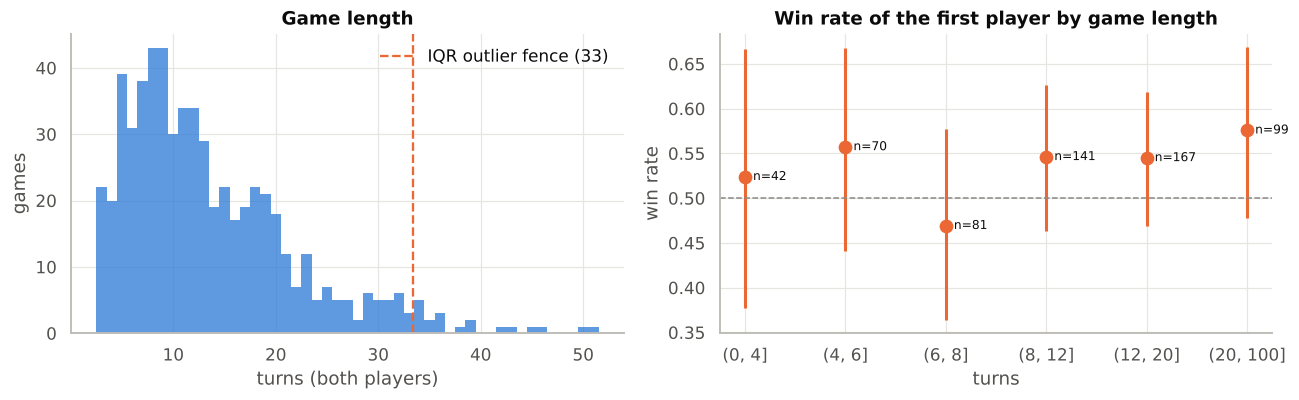

{'count': 600.0, 'mean': 13.6, 'std': 8.3, 'min': 3.0, '25%': 7.8, '50%': 11.5, '75%': 18.0, 'max': 51.0}
outlier games (long): 19


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(seat0["n_turns"], discrete=True, color=PALETTE[0], ax=axes[0], edgecolor="white")
axes[0].set_title("Game length"); axes[0].set_xlabel("turns (both players)"); axes[0].set_ylabel("games")
q1, q3 = seat0["n_turns"].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
axes[0].axvline(upper, color=PALETTE[1], ls="--", lw=1.5, label=f"IQR outlier fence ({upper:.0f})")
axes[0].legend(frameon=False)
fp = games_r[games_r["went_first"]]
fr = fp.groupby(pd.cut(fp["n_turns"], [0, 4, 6, 8, 12, 20, 100]), observed=True)["won"].agg(["sum", "size"])
ci = np.array([utils.wilson_ci(w, n) for w, n in zip(fr["sum"], fr["size"])])
rate = fr["sum"] / fr["size"]
x = np.arange(len(fr))
axes[1].vlines(x, ci[:, 0], ci[:, 1], color=PALETTE[1], lw=2)
axes[1].plot(x, rate.values, marker="o", markersize=8, color=PALETTE[1], lw=0)
for i, (r_, n_) in enumerate(zip(rate.values, fr["size"])):
    axes[1].text(i + 0.08, r_, f"n={n_}", fontsize=8, va="center")
axes[1].set_xticks(x, [str(b) for b in fr.index])
axes[1].axhline(0.5, color=GRAY, ls="--", lw=1)
axes[1].set_title("Win rate of the first player by game length"); axes[1].set_xlabel("turns"); axes[1].set_ylabel("win rate")
plt.tight_layout(); plt.show()
print(seat0["n_turns"].describe().round(1).to_dict())
print("outlier games (long):", int((seat0["n_turns"] > upper).sum()))

**Interpretation.** Game length is right-skewed: median 11.5 turns (both players together), mean 13.6, maximum 51. The IQR fence at
33 turns marks 19 long games as outliers. These are genuine games, not errors (every episode finished normally), most likely stalls in
which neither side can power up an attacker. We keep them; they matter for the time budget (600 s per player). The first player's win rate
stays slightly above 50 % at every game length, and all the intervals overlap. So the first-player edge does not depend strongly
on game length in random play.

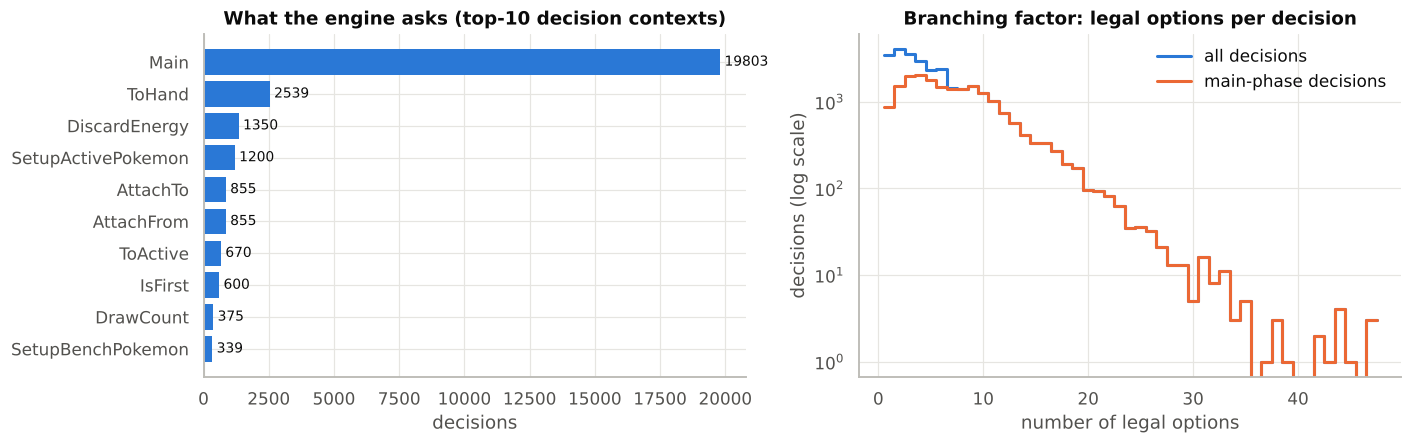

decisions per game: 48.0 | median options: 5.0 | max options: 47
share of single-option decisions: 0.12


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ctx = dec_r["context"].value_counts().head(10)
utils.bar_with_labels(axes[0], ctx)
axes[0].set_title("What the engine asks (top-10 decision contexts)"); axes[0].set_xlabel("decisions")
main = dec_r[dec_r["select_type"] == "Main"]
sns.histplot(dec_r["n_options"], discrete=True, color=PALETTE[0], ax=axes[1], element="step", fill=False, linewidth=2, label="all decisions")
sns.histplot(main["n_options"], discrete=True, color=PALETTE[1], ax=axes[1], element="step", fill=False, linewidth=2, label="main-phase decisions")
axes[1].set_yscale("log"); axes[1].set_title("Branching factor: legal options per decision")
axes[1].set_xlabel("number of legal options"); axes[1].set_ylabel("decisions (log scale)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print("decisions per game:", round(len(dec_r) / N_EDA_GAMES, 1),
      "| median options:", dec_r["n_options"].median(), "| max options:", dec_r["n_options"].max())
print("share of single-option decisions:", round((dec_r["n_options"] == 1).mean(), 3))

**Interpretation.** A game requires ~48 decisions. About 69 % of them are **main-phase** choices (19.8k). The rest are sub-decisions:
which cards to take from the deck (`ToHand`), which Energy to discard, which Pokémon to start with or attach to, and so on. The
branching factor is moderate but heavy-tailed: median 5 legal options, up to ~47. Only 12 % of decisions are forced (a single
option). This tells us that (1) the agent must handle many decision *types*, not just "which attack", and (2) the *number of
decisions* is the real challenge for search: even 5 options over ~48 decisions is far too many sequences for brute force.
Assignment 2 will therefore need selective search.

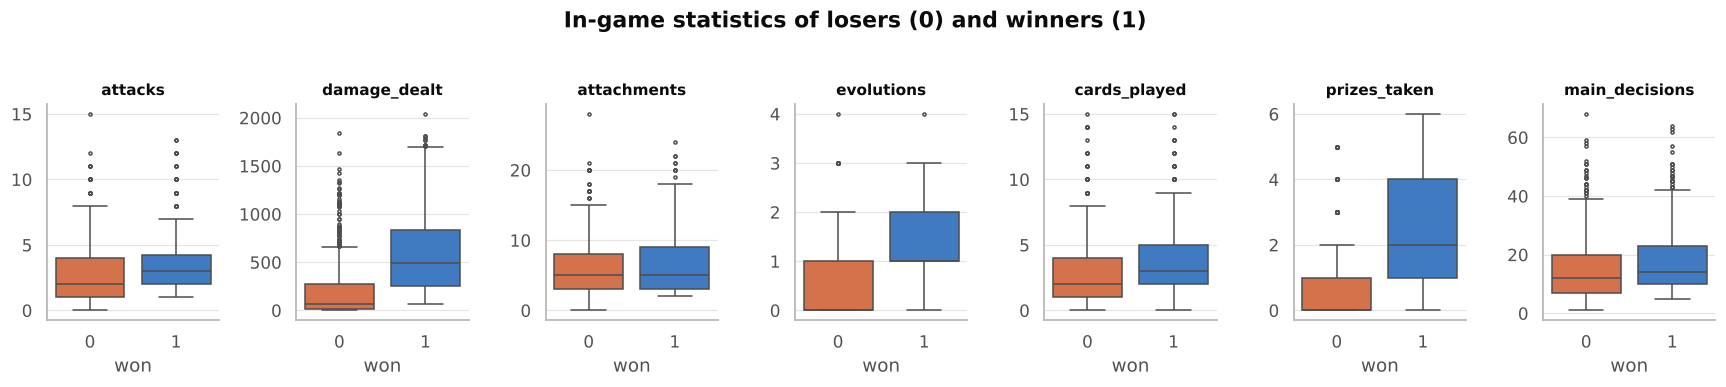

,went_first,attachments,attacks,main_decisions,cards_played,evolutions,damage_dealt,prizes_taken
correlation with won,0.08,0.095,0.121,0.124,0.135,0.411,0.462,0.51


In [19]:
feats = ["attacks", "damage_dealt", "attachments", "evolutions", "cards_played", "prizes_taken", "main_decisions"]
fig, axes = plt.subplots(1, len(feats), figsize=(16, 3.4))
for ax, f in zip(axes, feats):
    sns.boxplot(data=games_r, x="won", y=f, hue="won", ax=ax, palette=[PALETTE[1], PALETTE[0]], fliersize=2, linewidth=1, legend=False)
    ax.set_title(f, fontsize=10); ax.set_xlabel("won"); ax.set_ylabel("")
plt.suptitle("In-game statistics of losers (0) and winners (1)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

rel = games_r[feats + ["went_first", "won"]].astype(float).corr()["won"].drop("won").sort_values()
rel.to_frame("correlation with won").round(3).T

**Interpretation.** Winners take more Prize cards (ρ = 0.51 with `won`), deal more damage (0.46) and **evolve more often (0.41)**.
Evolving is the clearest *controllable* action linked to winning (an evolved Mega Abomasnow ex has 350 HP instead of 90). Playing
more cards and making more main-phase decisions also helps a little (0.12–0.14), whereas raw attachment counts barely matter
(0.10). Going first adds only 0.08. Some of these are consequences of winning rather than causes (a winner naturally deals more
damage), so they are *hints*, not proof. Still, they directly motivate the baseline's priorities: **evolve first, develop the
Bench, power up an attacker, attack with the highest expected damage**.

## 4. Preprocessing

All steps are implemented in `src/data.py` and were already used above. What we do and **why**:

| Step | What | Why |
|---|---|---|
| 1 | Read every column as text, keep `n/a` and empty separate | the file uses both markers inconsistently; the meaning of a blank depends on the card's supertype (table in 2.1) |
| 2 | **Pokémon:** Weakness / Resistance `n/a` → `"None"` | on a Pokémon a missing Weakness means it *has no weakness* (e.g. Dragon types) — real information, not missing data. The engine table confirms it (checked below) |
| 3 | Imputation: `Retreat = n/a` on a **Pokémon** → 0 | in the card game a Pokémon without a printed retreat cost retreats for free; the engine table confirms `retreatCost = 0` for all of them (checked below). Nothing else is imputed: HP / retreat / cost are missing **by design** for Trainers, Energy and abilities, and filling them (mean, 0 …) would invent values that do not exist |
| 4 | Cast HP, retreat, collection number to numbers | needed for statistics and plots |
| 5 | Parse `Cost` (`{W}{W}●`) → total / typed / colorless counts | energy symbols are a mini-language; counts are what the game logic needs |
| 6 | Parse `Damage` (`120`, `30×`, `90-`) → base number + modifier | `×` damage is variable, the printed number is only a multiplier |
| 7 | Flag abilities (`[Ability]`, `[Tera]` rows) | they live in the move column but are not attacks |
| 8 | Aggregate to **one row per card** | the CSV is long (1 row per move); most analyses and the deck need card-level rows |
| 9 | Join with the engine attack table on (Card ID, move name) | observations use `attackId`; the join gives every attack its cost and an **expected damage** |
| 10 | Encoding: one-hot for nominal card features (type, stage) | categories have no order, so label-encoding would create a fake ranking |
| 11 | Scaling: `StandardScaler` only for the logistic-regression model | the rule-based agent compares raw game quantities (HP, damage), scaling would only obscure them; the regularised linear model needs comparable feature scales |
| 12 | Win-probability features as **differences** (me − opponent) | symmetric, seat-independent, and the same feature works from both players' point of view |

In [20]:
print("Pokémon rows with missing HP after cleaning :", int(moves.loc[moves["supertype"] == "Pokémon", "hp"].isna().sum()))
nw = moves[(moves["supertype"] == "Pokémon") & (moves["weakness"] == "None")].merge(engine_cards[["cardId", "weakness"]], left_on="card_id", right_on="cardId", suffixes=("", "_engine"))
print(f"Pokémon rows with weakness 'None'          : {len(nw)}, engine weakness is null for {nw['weakness_engine'].isna().mean():.0%}")
imp = cards[cards["card_id"].isin(moves.loc[moves["retreat_imputed"], "card_id"])]
chk = imp.merge(engine_cards[["cardId", "retreatCost"]], left_on="card_id", right_on="cardId")
print(f"Pokémon with retreat imputed to 0          : {len(imp)} cards, engine retreatCost == 0 for {int((chk['retreatCost'] == 0).sum())}")
both = cards[cards["supertype"] == "Pokémon"].merge(engine_cards[["cardId", "hp", "retreatCost"]], left_on="card_id", right_on="cardId", suffixes=("", "_engine"))
print(f"CSV vs engine agreement (Pokémon)          : HP {(both['hp'] == both['hp_engine']).mean():.1%}, retreat {(both['retreat'] == both['retreatCost']).mean():.1%}")
print("Pokémon rows with missing retreat           :", int(moves.loc[moves["supertype"] == "Pokémon", "retreat"].isna().sum()))
print("attacks with unparsed damage                :", int((moves["damage_mod"] == "unparsed").sum()))
print("weakness values:", sorted(moves["weakness"].dropna().unique()))
moves[["card_id", "name", "stage", "hp", "type", "weakness", "move_name", "cost", "cost_total",
       "cost_typed", "damage", "damage_base", "damage_mod", "is_ability"]].iloc[[0, 37, 38, 39, 1255]]

Pokémon rows with missing HP after cleaning : 0
Pokémon rows with weakness 'None'          : 77, engine weakness is null for 100%
Pokémon with retreat imputed to 0          : 38 cards, engine retreatCost == 0 for 38
CSV vs engine agreement (Pokémon)          : HP 100.0%, retreat 100.0%
Pokémon rows with missing retreat           : 0
attacks with unparsed damage                : 0
weakness values: ['Darkness', 'Fighting', 'Fire', 'Grass', 'Lightning', 'Metal', 'None', 'Psychic', 'Water']


,card_id,name,stage,hp,type,weakness,move_name,cost,cost_total,cost_typed,damage,damage_base,damage_mod,is_ability
0,1,Basic {G} Energy,Basic Energy,NaN,Grass,NaN,NaN,n/a,NaN,NaN,n/a,NaN,none,False
37,30,Magcargo ex,Stage 1 Pokémon,270.0,Fire,Water,[Tera],n/a,NaN,NaN,n/a,NaN,none,True
38,30,Magcargo ex,Stage 1 Pokémon,270.0,Fire,Water,Hot Magma,{R}●,2.0,1.0,70,70.0,fixed,False
39,30,Magcargo ex,Stage 1 Pokémon,270.0,Fire,Water,Ground Burn,{R}{R}●,3.0,2.0,140,140.0,fixed,False
1255,723,Mega Abomasnow ex,Stage 1 Pokémon,350.0,Water,Metal,Hammer-lanche,{W}{W},2.0,2.0,100×,100.0,x,False


In [21]:
# Encoding example: card-level feature matrix (nominal -> one-hot), used later for deck building
card_features = pd.get_dummies(pokemon[["type", "stage"]], prefix=["type", "stage"], dtype=int)
card_features = pd.concat([pokemon[["card_id", "hp", "retreat", "max_damage", "min_cost"]].reset_index(drop=True),
                           card_features.reset_index(drop=True)], axis=1)
print("card feature matrix:", card_features.shape)
card_features.head(3)

card feature matrix: (1196, 18)


,card_id,hp,retreat,max_damage,min_cost,type_Colorless,type_Darkness,type_Dragon,type_Fighting,type_Fire,type_Grass,type_Lightning,type_Metal,type_Psychic,type_Water,stage_Basic Pokémon,stage_Stage 1 Pokémon,stage_Stage 2 Pokémon
0,21,120.0,1,100.0,1.0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,22,90.0,3,10.0,1.0,0,0,0,1,0,0,0,0,0,0,1,0,0
2,23,160.0,4,150.0,2.0,0,0,0,1,0,0,0,0,0,0,0,1,0


In [22]:
attack_table = data.build_attack_table(moves, engine_cards, engine_attacks)
print("attacks:", len(attack_table), "| matched to a CSV move:", f"{attack_table['matched_csv'].mean():.2%}")
print("unmatched:", attack_table.loc[~attack_table["matched_csv"], ["card_id", "move_name"]].to_dict("records"))
var = attack_table[(attack_table["engine_damage"] == 0) & (attack_table["damage_mod"] == "x")]
print("variable-damage attacks where est_damage comes from the CSV:", len(var))
card_db = data.build_card_db(engine_cards, attack_table)
deck_attacks = [a for c in set(deck) for a in card_db["cards"][str(c)]["attacks"]]
attack_table[attack_table["attack_id"].isin(deck_attacks)][["card_id", "move_name", "energies", "engine_damage",
                                                            "damage_base", "damage_mod", "est_damage"]]

attacks: 1755 | matched to a CSV move: 99.94%
unmatched: [{'card_id': 24, 'move_name': 'Comet Punch'}]
variable-damage attacks where est_damage comes from the CSV: 120


,card_id,move_name,energies,engine_damage,damage_base,damage_mod,est_damage
1041,721,Riptide,[3],0,20.0,x,40.0
1042,721,Swirling Waves,"[3, 3, 0]",130,130.0,fixed,130.0
1043,722,Beat,[3],10,10.0,fixed,10.0
1044,722,Icy Snow,"[3, 3]",30,30.0,fixed,30.0
1045,723,Hammer-lanche,"[3, 3]",0,100.0,x,200.0
1046,723,Frost Barrier,"[3, 3, 3]",200,200.0,fixed,200.0


**Interpretation.** After cleaning, no Pokémon row lacks HP or retreat. The 77 rows that became "no Weakness" and the 38 cards
whose retreat was set to 0 agree **100 %** with the engine's own card table, and HP and retreat agree with the engine for every
Pokémon. So the imputation follows the game's rules, not a guess. Every damage string parses. The engine attack table matches a CSV
move for **99.94 %** of attacks (the one miss, 'Comet Punch', is spelled differently).

For our deck the join is essential. Hammer-lanche (the deck's main attack) and Riptide have **engine damage 0** because their
damage is variable. Our estimate (CSV base × 2) rates them 200 and 40. Without it the agent would treat its best attack as
useless.

## 5. Baseline model

In a simulation competition the "model" is the **policy**. We compare three agents, all using the same sample deck
(so differences come from play, not from the deck):

* **Random** – a uniformly random legal answer (same as Kaggle's built-in `random` agent).
* **First** – always the first legal options (Kaggle's built-in `first` agent). Surprisingly strong: the engine lists
  "play / attach" options before "attack" and "end turn", so it develops its board before attacking.
* **Heuristic (our baseline)** – a rule-based agent driven by the preprocessed card data. In the main phase it scores every
  legal option and plays the best one; the engine comes back after each action, so the turn is built greedily:
  evolve → bench Basics → Energy that brings an attack closer → items / supporters / abilities → (retreat) → **attack with
  the highest expected damage** (Weakness ×2, Resistance −30) → end turn. Sub-decisions (searching, discarding, choosing
  targets, paying Energy) use a simple card-value function. Every answer is validated before it is returned.

**Train / validation protocol.** There is no fixed dataset, so the analogue of a split is: *training games* are used to
choose the heuristic's switches, then a **fresh, independent batch of validation games** gives the reported score.
The simulator seeds itself from hardware entropy, so every batch is new, unseen data (no leakage), and Python-side randomness is seeded.

In [23]:
first_pol = models.FirstPolicy(deck)
rand_pol = models.RandomPolicy(deck, seed=7)

import itertools
grid = []
for retreat, starter, evo in itertools.product([True, False], ["hp", "evolution"], [False, True]):
    pol = models.HeuristicPolicy(card_db, deck, seed=1, retreat=retreat, starter=starter, evo_aware_energy=evo)
    g, _, _ = models.evaluate(pol, {"first": first_pol}, N_TUNE_GAMES, verbose=False)
    r = models.win_rate_table(g, "heuristic").iloc[0]
    grid.append({"retreat": retreat, "starter": starter, "evo_aware_energy": evo,
                 "train_win_rate": r.win_rate, "ci_low": r.ci_low, "ci_high": r.ci_high})
grid = pd.DataFrame(grid).sort_values("train_win_rate", ascending=False).reset_index(drop=True)
grid.round(3)

,retreat,starter,evo_aware_energy,train_win_rate,ci_low,ci_high
0,False,evolution,True,0.640,0.561,0.712
1,True,hp,False,0.627,0.547,0.700
2,True,evolution,False,0.600,0.520,0.675
3,False,hp,False,0.593,0.513,0.669
4,True,evolution,True,0.580,0.500,0.656
5,True,hp,True,0.573,0.493,0.650
6,False,hp,True,0.533,0.454,0.611
7,False,evolution,False,0.507,0.427,0.586


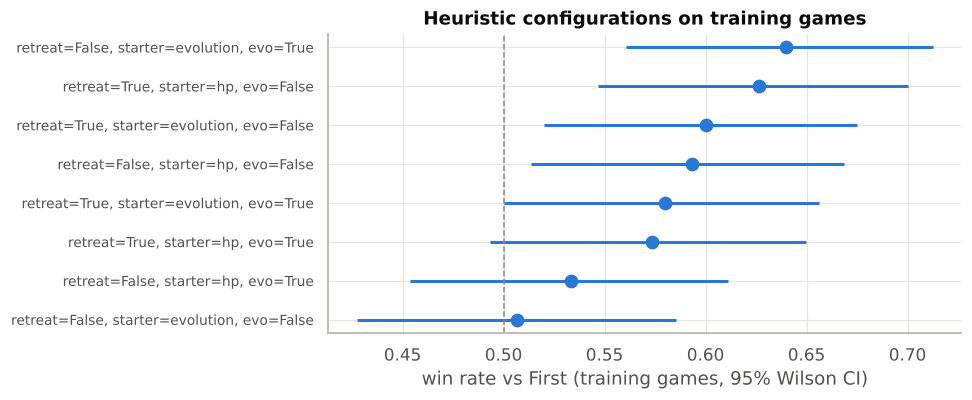

selected configuration: {'retreat': False, 'starter': 'evolution', 'evo_aware_energy': True}


In [24]:
labels = [f"retreat={r.retreat}, starter={r.starter}, evo={r.evo_aware_energy}" for r in grid.itertuples()]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(grid))
ax.hlines(y, grid["ci_low"], grid["ci_high"], color=PALETTE[0], lw=2)
ax.plot(grid["train_win_rate"], y, "o", color=PALETTE[0], markersize=8)
ax.axvline(0.5, color=GRAY, ls="--", lw=1)
ax.set_yticks(y, labels, fontsize=9); ax.invert_yaxis()
ax.set_xlabel("win rate vs First (training games, 95% Wilson CI)")
ax.set_title("Heuristic configurations on training games")
plt.tight_layout(); plt.show()
best = grid.iloc[0][["retreat", "starter", "evo_aware_energy"]].to_dict()
best = {k: (bool(v) if k != "starter" else v) for k, v in best.items()}
print("selected configuration:", best)

**Interpretation.** All eight configurations score at or above 50 % against First on the training games (51–64 %), but their
**confidence intervals overlap heavily**. With 150 games per configuration the switches are hard to tell apart, and their ranking changed
between our development runs. We select the best one (no retreat, start with an evolvable Basic, Energy aimed at the evolution's
attack). That choice makes sense for this deck: retreating costs 3–4 Energy, and Snover → Mega Abomasnow ex is the win condition.
Because we picked the maximum of eight noisy estimates, its training score (64.0 %) is optimistic. The honest number comes from the
fresh validation games below.

In [25]:
heur = models.HeuristicPolicy(card_db, deck, seed=11, **best)
games_v, dec_v, snap_v = models.evaluate(heur, {"random": rand_pol, "first": first_pol}, N_VALID_GAMES)
valid = models.win_rate_table(games_v, "heuristic")
valid.round(3)

heuristic vs random:


  80/400 games  (9s)


  160/400 games  (18s)


  240/400 games  (26s)


  320/400 games  (36s)


  400/400 games  (44s)
heuristic vs first:


... (2 outputs left out)

  240/400 games  (30s)


  320/400 games  (39s)


  400/400 games  (50s)


,opponent,games,wins,win_rate,ci_low,ci_high,win_rate_going_first,win_rate_going_second
0,first,400,242,0.605,0.556,0.652,0.730,0.480
1,random,400,373,0.932,0.904,0.953,0.951,0.875


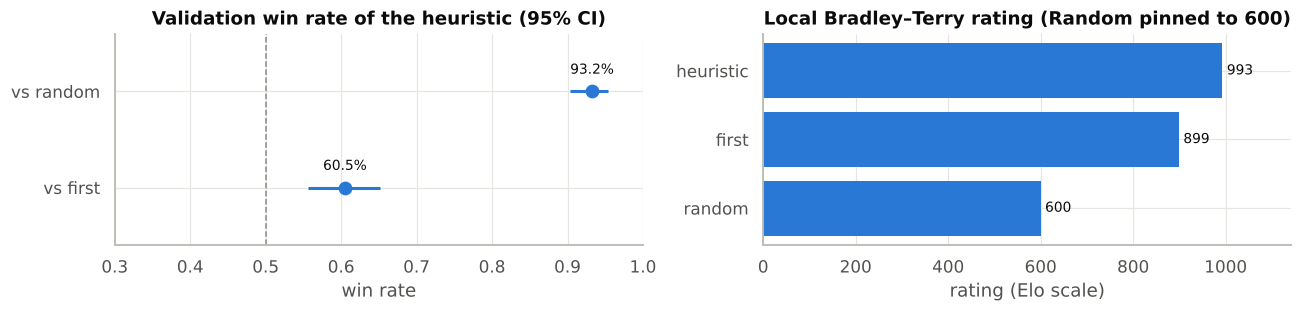

heuristic    993.1
first        899.3
random       600.0


In [26]:
# Round-robin for a local Bradley-Terry rating: add Random vs First games
games_rf, _, _ = data.simulate_games(models.as_kaggle_agent(rand_pol), models.as_kaggle_agent(first_pol),
                                     N_VALID_GAMES // 2, names=("random", "first"), verbose=False)
pool = pd.concat([games_v, games_rf], ignore_index=True)
ratings = models.bradley_terry(pool, anchor="random", anchor_value=600)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.0))
y = np.arange(len(valid))
axes[0].hlines(y, valid["ci_low"], valid["ci_high"], color=PALETTE[0], lw=2)
axes[0].plot(valid["win_rate"], y, "o", color=PALETTE[0], markersize=8)
for i, r in enumerate(valid.itertuples()):
    axes[0].text(r.win_rate, i + 0.15, f"{r.win_rate:.1%}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(-0.6, len(valid) - 0.4)
axes[0].axvline(0.5, color=GRAY, ls="--", lw=1)
axes[0].set_yticks(y, ["vs " + o for o in valid["opponent"]]); axes[0].set_xlim(0.3, 1.0)
axes[0].set_title("Validation win rate of the heuristic (95% CI)"); axes[0].set_xlabel("win rate")
utils.bar_with_labels(axes[1], ratings.round(0), fmt="{:.0f}")
axes[1].set_xlim(0, ratings.max() * 1.15)
axes[1].set_title("Local Bradley–Terry rating (Random pinned to 600)"); axes[1].set_xlabel("rating (Elo scale)")
plt.tight_layout(); plt.show()
print(ratings.round(1).to_string())

**Interpretation.** On **400 fresh validation games per opponent** the heuristic wins **93.2 %** (95 % CI 90.4–95.3 %) against
Random and **60.5 %** (55.6–65.2 %) against First. Both intervals exclude 50 %, so the baseline is clearly better than both
references. As expected, the score against First fell from 64.0 % (training) to 60.5 %: the selection was optimistic.

Turn order matters much more between competent agents. Against First we win 73.0 % when going first but only 48.0 % when going
second, a 25-point gap, compared with ~8 points in random play. On the Bradley–Terry scale (Random pinned to 600) the pool ranks
**heuristic 993 > first 899 > random 600**. A 94-point gap corresponds to an expected score of ≈ 0.63 against First, consistent
with the observed win rate. This is our offline "competition metric". The real Kaggle μ depends on the other teams' agents, so it
is not on the same scale.

### 5.1 A simple supervised baseline: win-probability model

Search-based agents (our plan for Assignment 2) need a way to judge a position. As a first supervised model we predict
**P(player wins | board at the start of their turn)** with logistic regression on heuristic-vs-heuristic self-play games.

* features: turn, going first, and *me − opponent* differences (Prize cards left, Pokémon in play, HP in play, Energy in play,
  Active HP/Energy, hand size, deck size);
* preprocessing: `StandardScaler` → `LogisticRegression` (pipeline, fitted on training rows only);
* **split: 80 / 20 grouped by game** – all turns of one game stay on the same side, otherwise near-identical consecutive positions
  would leak into validation;
* metric: ROC-AUC and log-loss on the validation games, compared with a constant predictor and a one-feature
  "Prize-difference" rule.

In [27]:
h1 = models.HeuristicPolicy(card_db, deck, seed=21, **best); h1.name = "heuristic_A"
h2 = models.HeuristicPolicy(card_db, deck, seed=22, **best); h2.name = "heuristic_B"
_, _, snaps = data.simulate_games(models.as_kaggle_agent(h1), models.as_kaggle_agent(h2), N_VALUE_GAMES,
                                  names=("heuristic_A", "heuristic_B"), verbose=False)
snaps = snaps[snaps["turn"] >= 1].reset_index(drop=True)
print("snapshots:", snaps.shape, "| games:", snaps["game_id"].nunique(), "| positive rate:", round(snaps["won"].mean(), 3))
value_model, value_metrics, (tr_idx, va_idx) = models.train_value_model(snaps)
pd.Series(value_metrics).round(4).to_frame("value")

snapshots: (2765, 29) | games: 500 | positive rate: 0.563


,value
train_rows,2194.0000
valid_rows,571.0000
train_games,400.0000
valid_games,100.0000
auc,0.8021
log_loss,0.5284
accuracy,0.7513
auc_prize_rule,0.7597
log_loss_constant,0.6854


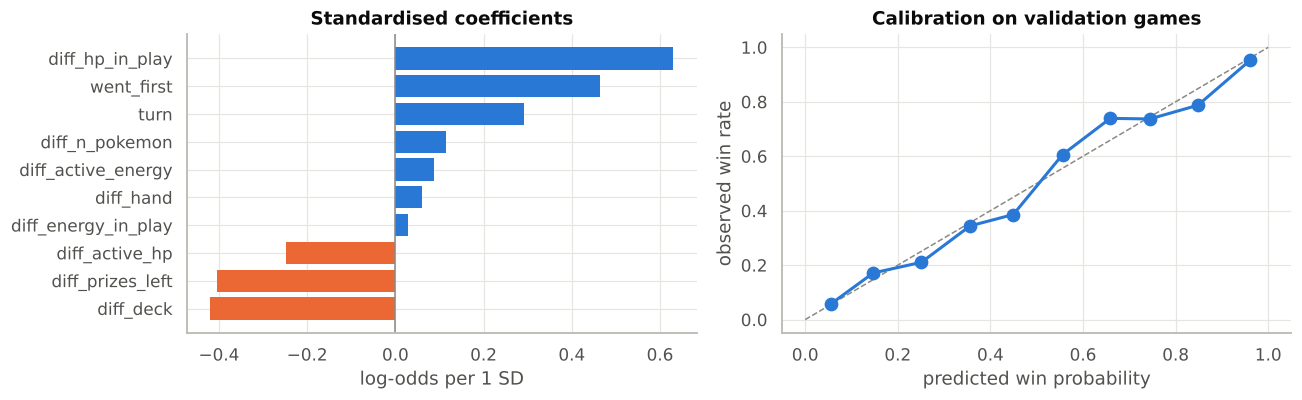

In [28]:
coef = pd.Series(value_model[-1].coef_[0], index=models.VALUE_FEATURES).sort_values()
p_va = value_model.predict_proba(snaps.loc[va_idx, models.VALUE_FEATURES].astype(float))[:, 1]
calib = pd.DataFrame({"p": p_va, "y": snaps.loc[va_idx, "won"].to_numpy()})
calib["bin"] = pd.cut(calib["p"], np.linspace(0, 1, 11))
cal = calib.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colors = [PALETTE[1] if v < 0 else PALETTE[0] for v in coef.values]
axes[0].barh(coef.index, coef.values, color=colors)
axes[0].axvline(0, color=GRAY, lw=1)
axes[0].set_title("Standardised coefficients"); axes[0].set_xlabel("log-odds per 1 SD")
axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
axes[1].plot(cal["pred"], cal["obs"], marker="o", markersize=8, color=PALETTE[0])
axes[1].set_title("Calibration on validation games"); axes[1].set_xlabel("predicted win probability"); axes[1].set_ylabel("observed win rate")
plt.tight_layout(); plt.show()

**Interpretation.** The win-probability model reaches **ROC-AUC 0.80** and **log-loss 0.53** on 100 held-out games. That beats a
constant predictor (log-loss 0.69) and the one-feature Prize-difference rule (AUC 0.76). The calibration curve stays close to the
diagonal, so the probabilities can be used as they are (accuracy 75 %).

The coefficients are game-sensible: more HP in play than the opponent, going first and more Pokémon in play help, while having
more Prize cards left than the opponent (i.e. being behind) hurts. `diff_deck` is also negative: having *more* cards left in the
deck means the opponent has drawn more cards and found their pieces faster. The rows are slightly imbalanced (56 % positives)
because the eventual winner usually gets the last turn and so contributes one more snapshot; the grouped split keeps this from
leaking. This model is the **position evaluator** we plan to plug into look-ahead search in Assignment 2.

## 6. Kaggle submission

Kaggle expects `submission.tar.gz` with `main.py` at the top level plus `deck.csv`. `utils.build_submission` writes:
* `main.py` – loads the policy and defines `agent(obs)` as the **last** callable (Kaggle uses the last callable it finds);
* `ptcg_policy.py` – an unchanged copy of `src/models.py` (the policy part only needs the standard library);
* `card_db.json` – the preprocessed card/attack data for the 9 distinct cards in our deck;
* `deck.csv` – the sample deck.

Before uploading we reproduce Kaggle's **validation episode** locally: the bundle is loaded from its file path exactly like
Kaggle does and plays a BO3 match against a copy of itself, then a few BO3 matches against Random.

In [29]:
tar_path = utils.build_submission(card_db, deck, out_dir="build", policy_source="src/models.py")
import tarfile
with tarfile.open(tar_path) as t:
    print(tar_path, f"{tar_path.stat().st_size / 1024:.1f} KB ->", t.getnames())

build/submission.tar.gz 8.9 KB -> ['card_db.json', 'deck.csv', 'main.py', 'ptcg_policy.py']


In [30]:
make = data.import_make()
main_py = "build/agent/main.py"
env = make("cabt", configuration={"bo": 3})
env.run([main_py, main_py])
print("self-play BO3:", [s.status for s in env.state], [s.reward for s in env.state], "games:", env.result)

results = []
for i in range(6):
    pair = [main_py, models.as_kaggle_agent(rand_pol)] if i % 2 == 0 else [models.as_kaggle_agent(rand_pol), main_py]
    env = make("cabt", configuration={"bo": 3})
    env.run(pair)
    me = 0 if i % 2 == 0 else 1
    results.append({"match": i, "seat": me, "status": env.state[me].status, "reward": env.state[me].reward})
pd.DataFrame(results)

self-play BO3: ['DONE', 'DONE'] [1, -1] games: [2, 1, 0]


,match,seat,status,reward
0,0,0,DONE,1
1,1,1,DONE,1
2,2,0,DONE,1
3,3,1,DONE,1
4,4,0,DONE,1
5,5,1,DONE,1


**Local check.** Loaded from its file path exactly as Kaggle does, the bundle finished the self-play BO3 without errors
(both seats `DONE`, no invalid actions) and won 6/6 BO3 matches against Random. So it should pass Kaggle's validation episode.

**Leaderboard score.** We uploaded `build/submission.tar.gz` on the competition page (*Submit Agent*) on 13 Nov 2026. It passed the
validation episode (status *Complete*) and joined the ladder at μ₀ = 600; its μ moves as games are played. Screenshot: `submissions/assignment1_score.png`.

| Submission | Description | Kaggle score (μ) |
|---|---|---|
| 1 | Heuristic baseline + sample deck | **419.9** (13 Nov 2026, 22:29 TRT; started at 600.0) |

![Kaggle score](submissions/assignment1_score.png)

**Interpretation.** About one hour of ladder games moved μ from 600 down to **≈ 400** (394.7 at 22:25, 419.9 at 22:29 in the screenshot). For comparison, the top of the leaderboard
is at **≈ 1,589** (#1, 13 Nov 2026). Our offline results show that the heuristic is clearly better than Random and First, but the
ladder is full of much stronger agents. Many of them use search or learning and better decks, so a greedy rule-based policy with
the fragile sample deck loses most of its games there. The gap of ~1,200 rating points is the room for Assignment 2. μ will keep
moving (σ is still large), so the number above is a snapshot.

## 7. Conclusion
**Key findings**
* The competition is a *simulation* task: the "data" are the card pool and the games we generate. Kaggle ranks agents by a skill
  rating (μ₀ = 600, final Bradley–Terry), so offline we report **win rates with Wilson CIs** and a **local Bradley–Terry rating**.
* The card CSV is long-format (one row per move) and marks missing values inconsistently. A blank means "not applicable" for
  Trainers and Energy but "none / free" for Pokémon. We resolved this per supertype and verified it 100 % against the engine.
* The card pool is Pokémon-heavy. HP, damage and retreat cost all scale with evolution stage and ex status, and the outliers
  (HP > 245) are all ex / Mega ex, a separate population rather than errors. Variable-damage attacks need an estimate because
  the engine table reports 0 for them.
* In random play ~90 % of games end because a player runs out of Pokémon, not by Prize cards. The sample deck has only 6 Basics
  (46 % mulligan risk), so board presence decides games. Winners evolve more and take more Prizes; the first-player edge is
  small in random play (54 %) but large between competent agents (73 % vs 48 %).
* **Baseline:** a rule-based agent driven by the cleaned card data (evolve → bench → Energy → trainers → best expected attack)
  wins **93 %** against Random and **61 %** against First on fresh validation games (local BT rating 993 vs 899 vs 600). A
  logistic-regression win-probability model on self-play positions reaches **AUC 0.80**.
* **On Kaggle** the same agent dropped from μ₀ = 600 to **≈ 420** within an hour, while the leaderboard leader is at ≈ 1,589.
  Beating simple reference agents is not enough on the ladder: deck quality and look-ahead matter much more.

**Next steps (Assignment 2)**
1. **Deck building:** use the card-level table to build decks with more Basics and better Energy/attacker ratios; evaluate them
   in round-robins.
2. **Look-ahead search:** the SDK's forward model (`search_begin` / `search_step`) lets the agent simulate its own turn. Combine it
   with the win-probability model as the leaf evaluator (one-turn look-ahead first, then MCTS within the 600 s budget).
3. **Better targets for learning:** download Kaggle's daily top-episode replays (same format as our parser) for
   behaviour cloning, and retrain the value model on stronger games.
4. **Stronger evaluation:** more games per comparison, paired seat-swapped matches, and BO3 matches as on the ladder.

---
**Sources / credits.** Competition overview, rules and data description (Kaggle); simulator API (`cg/api.py` in the
sample submission and <https://matsuoinstitute.github.io/cabt/>); `kaggle-environments` (`cabt` environment). The
random/first reference agents re-implement the behaviour of the built-in `kaggle-environments` agents. No public Kaggle
notebook code was copied or adapted.